In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import roc_curve, auc,  roc_auc_score
from scipy.stats import randint,uniform

df=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv',index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')
df.head()

,age,num.co,edu,charges,totcst,avtisst,hday,meanbp,wblc,hrt,...,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,0,11.000000,9715.0,31100.865401,7.000000,1,97.0,6.000000,69.0,...,4,1,2,0,2,0,0,0,0,0
1,60.33899,2,12.000000,34496.0,31100.865401,29.000000,3,43.0,17.097656,112.0,...,7,3,2,1,0,5,1,1,0,0
2,52.74698,2,12.000000,41094.0,31100.865401,13.000000,4,70.0,8.500000,88.0,...,7,3,1,1,0,5,1,0,0,0
3,42.38498,2,11.000000,3075.0,31100.865401,7.000000,1,75.0,9.099609,88.0,...,4,1,1,1,2,1,1,0,0,0
4,79.88495,1,11.749662,50127.0,31100.865401,18.666656,3,59.0,13.500000,112.0,...,1,4,0,1,0,1,0,0,0,0


## 🛑 **Process to obtain the best model**

## 🛑 Task 1.2. PCA:  **Prediction of HospDeath**

---



### 🛑FEATURE SELECTION

1. Improves Model Accuracy: By removing irrelevant features, the model can focus on the most important data points, leading to better performance.

2. Reduces Overfitting: Too many features can prevent your model from learning noise in the data. Reducing the feature set can help mitigate overfitting.
Speeds up Training: Less data means faster computation. Feature selection can significantly reduce the training time, especially with large datasets.

3. Enhances Interpretability: With fewer features, it’s easier to understand how the model makes decisions

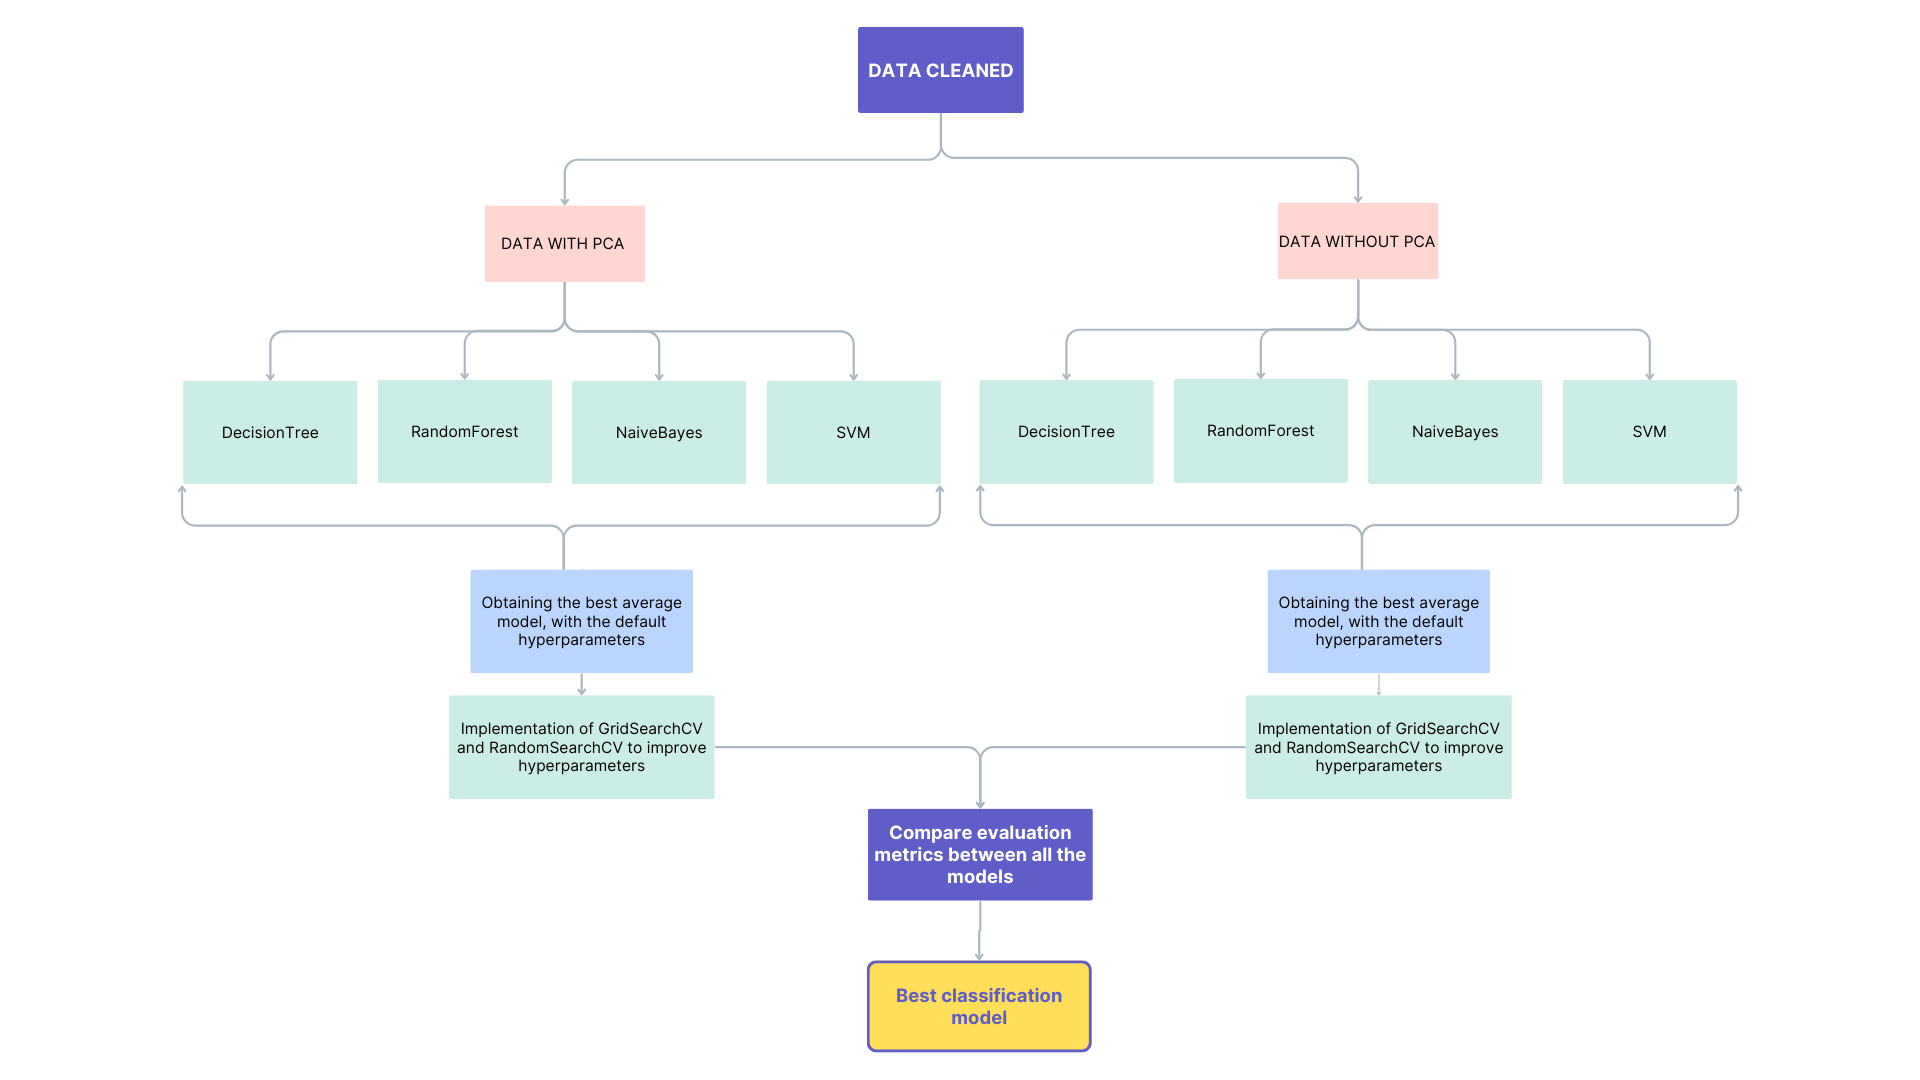

### 🛑 DATA SPLICING WE WILL USE STRATIFIED KFOLD

- First, we separate the data into the target variable and the features. It is crucial to identify and save the names of the qualitative columns, since principal component analysis (PCA) cannot be applied to them.

In [2]:
target=df['hospdead']
features=df.drop(['death','hospdead'],axis=1)
categorical_features_cols= categorical_features.drop(['death','hospdead'],axis=1).columns

- We are using a 70/10/20 data split strategy, but this time, we will apply a stratified k-fold approach. Specifically, we will calculate 10 folds: 5 external folds and 2 internal folds for validation. 
    
    The external folds will determine the training and testing splits, while the internal folds will further divide the training data into training and validation sets. This ensures a robust evaluation process by maintaining the data distribution and minimizing potential biases.


Cumulative explained variance for each number of components: [0.13674187 0.22794288 0.31095165 0.37984993 0.43403474 0.48637089
 0.53485429 0.57919732 0.62243166 0.66439496 0.70450693 0.74260374
 0.77908123 0.81519616 0.84785004 0.87996789 0.91023135 0.93910713
 0.96415792 0.98790845 0.99576555 1.        ]


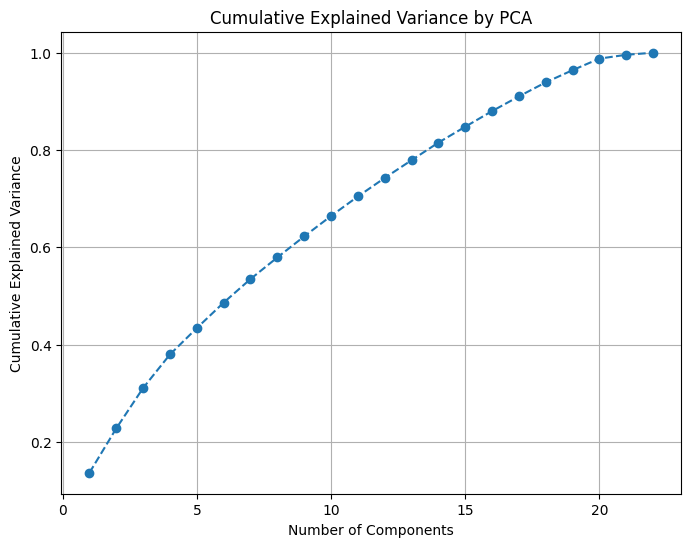

The optimal number of components to capture 85% of the variance is: 16


/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75683/54009021.py:112: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)


Cumulative explained variance for each number of components: [0.13696163 0.22907346 0.30901015 0.37933616 0.43079218 0.48168714
 0.52940119 0.57406517 0.61827602 0.65967021 0.69957241 0.73766121
 0.77443213 0.81069444 0.84391434 0.87644643 0.90749587 0.93610306
 0.96207516 0.98554764 0.99616263 1.        ]


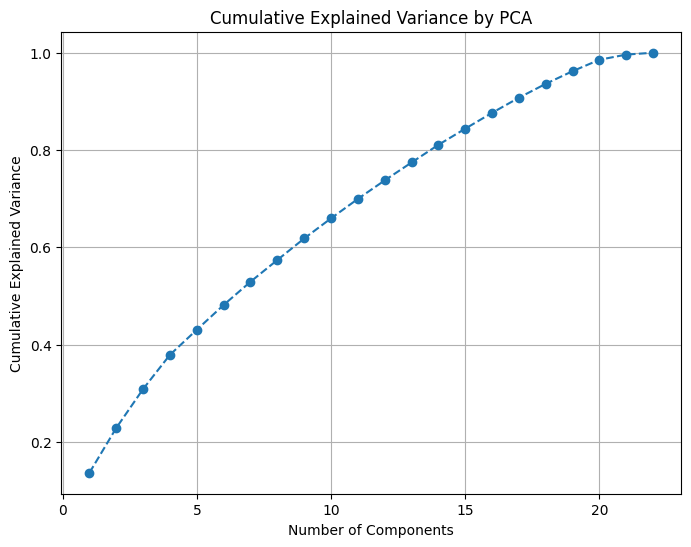

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.1380375  0.22911551 0.30960301 0.37975649 0.43201848 0.48410927
 0.53282027 0.57763313 0.62212595 0.66421912 0.70517307 0.74344282
 0.78041552 0.81500195 0.84834658 0.87978004 0.90947546 0.93841135
 0.96351324 0.98773972 0.99608751 1.        ]


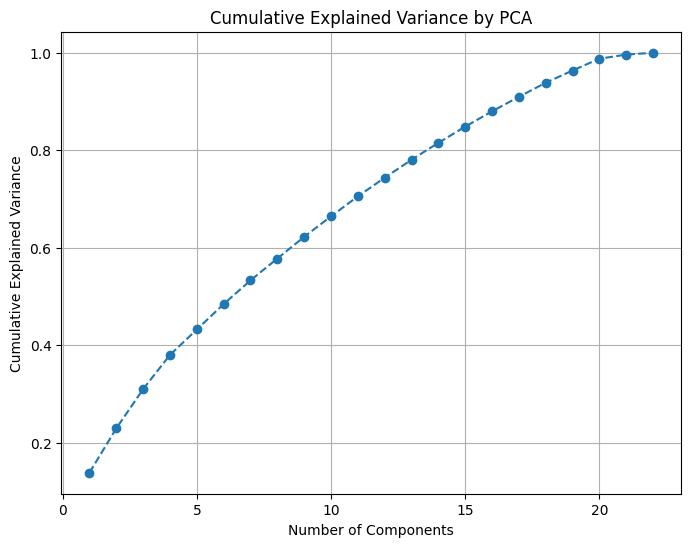

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13660216 0.22844305 0.31063976 0.37988637 0.43267823 0.48357356
 0.53134018 0.57652854 0.61915237 0.66137691 0.70152496 0.74066524
 0.77785501 0.81323553 0.84751868 0.88010642 0.90985769 0.93899402
 0.96381314 0.98724234 0.99609465 1.        ]


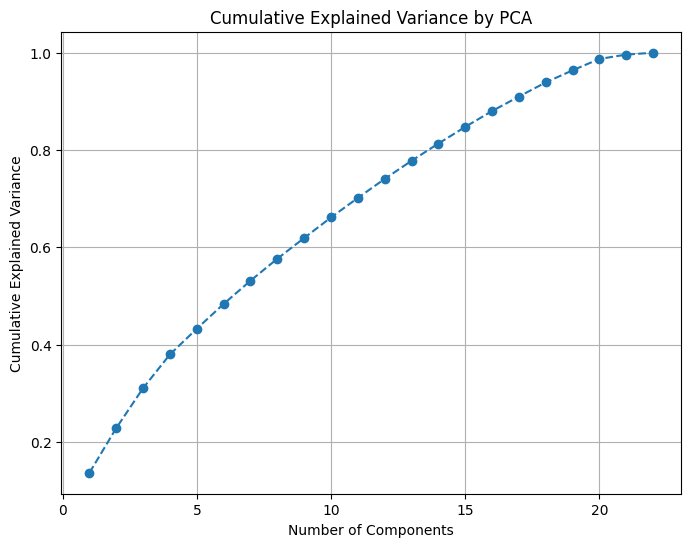

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13686956 0.22816608 0.30936031 0.37813413 0.43017564 0.481365
 0.53097031 0.57652136 0.61981264 0.6622104  0.70294903 0.74022974
 0.77687977 0.81335561 0.84674047 0.87914921 0.9082663  0.93681981
 0.96304699 0.98619359 0.99606928 1.        ]


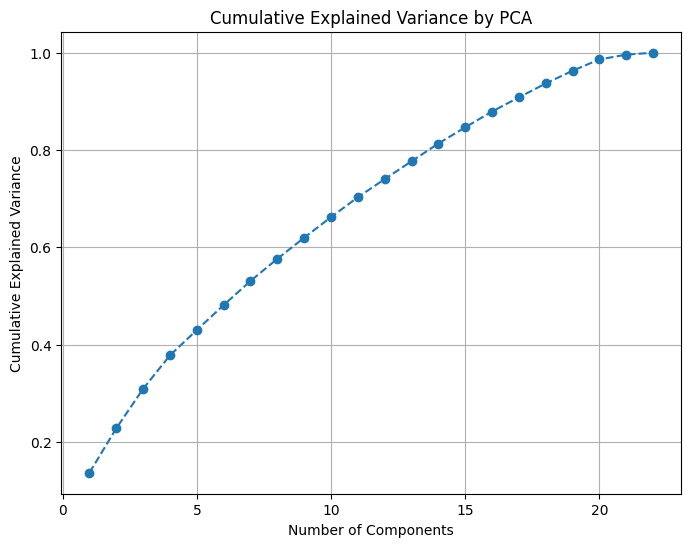

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13648203 0.22833976 0.30966563 0.37895403 0.43226105 0.48426732
 0.53154886 0.577359   0.620714   0.66137217 0.7011912  0.73936747
 0.77660877 0.81166005 0.84544648 0.87817068 0.90831131 0.93733236
 0.96254863 0.98593469 0.99585276 1.        ]


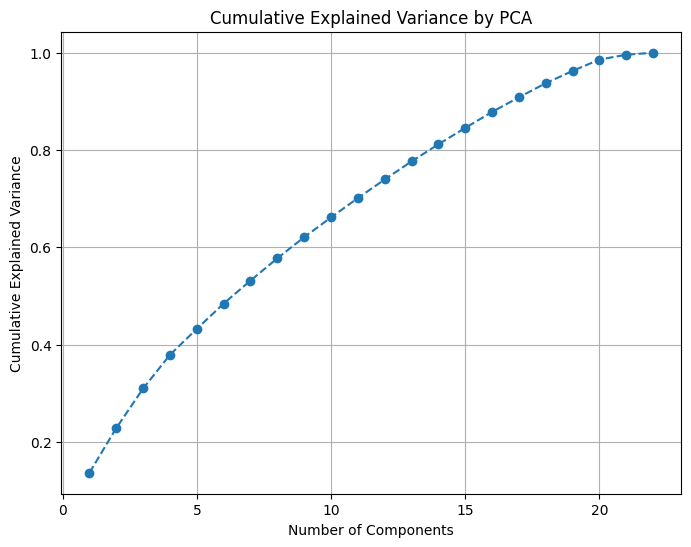

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13261305 0.22464293 0.30605606 0.37503159 0.42765571 0.47962082
 0.52745084 0.57325364 0.61719344 0.65914907 0.69994989 0.73844839
 0.77569914 0.810932   0.8449229  0.8774655  0.90772466 0.93653965
 0.96194231 0.98631559 0.99600312 1.        ]


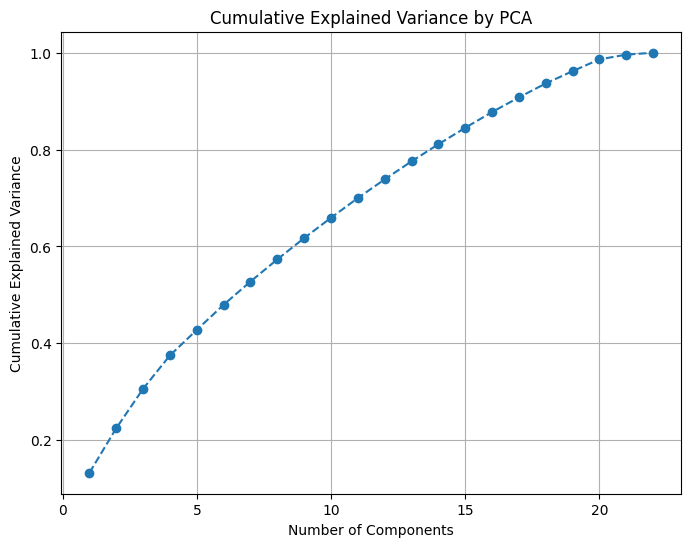

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.14091213 0.23211005 0.31510807 0.38331842 0.43652171 0.48853906
 0.53613699 0.58121052 0.62518506 0.66655508 0.70688756 0.74493225
 0.78175819 0.81772642 0.85074365 0.88290815 0.9116915  0.93932266
 0.96433074 0.98763994 0.99593736 1.        ]


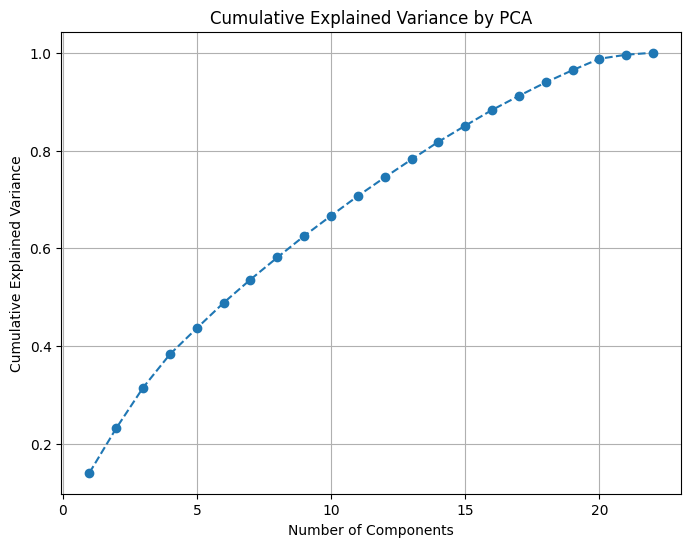

The optimal number of components to capture 85% of the variance is: 15
Cumulative explained variance for each number of components: [0.13520055 0.22705704 0.3071932  0.37541862 0.42896842 0.48012896
 0.52914574 0.57409201 0.61776351 0.66071707 0.70164185 0.73945707
 0.7758588  0.8110824  0.8451787  0.87797806 0.90920906 0.93749368
 0.96214428 0.98638162 0.996061   1.        ]


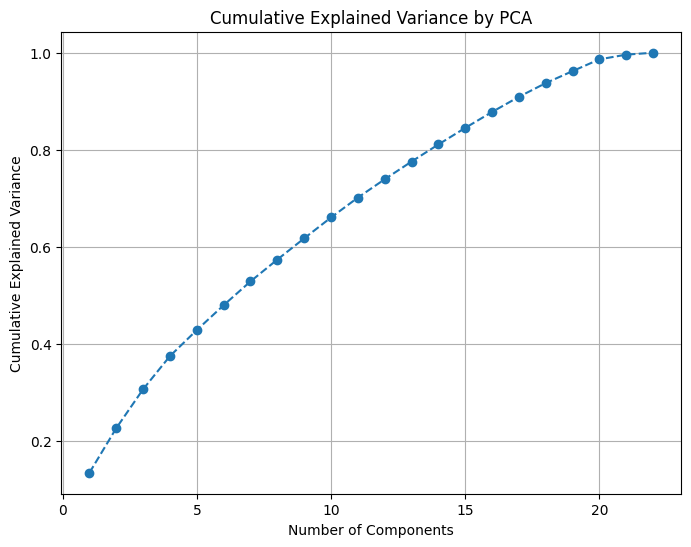

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13504822 0.22839381 0.31389477 0.38383777 0.43570935 0.48732264
 0.53422726 0.57899221 0.62336026 0.66416281 0.70412353 0.74251544
 0.77906878 0.81431759 0.84709589 0.87901541 0.90947949 0.9378641
 0.96293932 0.98670407 0.99604523 1.        ]


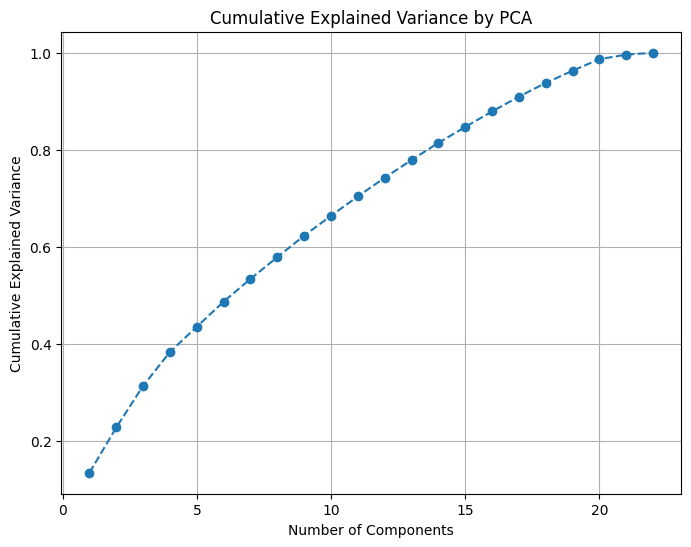

The optimal number of components to capture 85% of the variance is: 16
            Model  Accuracy  Precision    Recall  F1 Score       AUC
0   Decision Tree  0.868899   0.753394  0.731868  0.742475  0.824236
1   Random Forest  0.913167   0.822650  0.846154  0.834236  0.891325
2     Naïve Bayes  0.904086   0.770833  0.894505  0.828077  0.900964
3             SVM  0.909194   0.788650  0.885714  0.834369  0.901541
4   Decision Tree  0.884222   0.758763  0.808791  0.782979  0.859637
5   Random Forest  0.920545   0.826087  0.876923  0.850746  0.906327
6     Naïve Bayes  0.896708   0.770297  0.854945  0.810417  0.883096
7             SVM  0.910329   0.790607  0.887912  0.836439  0.903023
8   Decision Tree  0.876844   0.762115  0.760440  0.761276  0.838904
9   Random Forest  0.923383   0.837553  0.872527  0.854682  0.906807
10    Naïve Bayes  0.906924   0.785855  0.879121  0.829876  0.897862
11            SVM  0.912599   0.809035  0.865934  0.836518  0.897389
12  Decision Tree  0.875142   0.

In [3]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_pca = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])
# Diccionario para almacenar los DataFrames procesados
pca_data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        scaler = StandardScaler()
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_test = scaler.transform(X_test_quantitative)

        # Aplicar PCA
        pca = PCA()
        pca.fit(X_scaled_train)

        # Obtener y mostrar la varianza acumulada
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = explained_variance.cumsum()
        print(f"Cumulative explained variance for each number of components: {cumulative_variance}")

        # Graficar la varianza acumulada
        plt.figure(figsize=(8, 6))
        plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
        plt.title('Cumulative Explained Variance by PCA')
        plt.xlabel('Number of Components')
        plt.ylabel('Cumulative Explained Variance')
        plt.grid(True)
        plt.show()

        # Determinar el número óptimo de componentes
        optimal_components = next(i for i, value in enumerate(cumulative_variance) if value >= 0.85) + 1
        print(f"The optimal number of components to capture 85% of the variance is: {optimal_components}")

        # Aplicar PCA con el número óptimo de componentes
        pca_optimal = PCA(n_components=optimal_components)
        X_pca_optimal_train = pca_optimal.fit_transform(X_scaled_train)
        X_pca_optimal_val = pca_optimal.transform(X_scaled_val)
        X_pca_optimal_test = pca_optimal.transform(X_scaled_test)

        # Crear DataFrames para las componentes principales
        original_X_train_index = X_train.index
        original_X_val_index = X_val.index
        original_X_test_index = X_test.index

        pca_X_train = pd.DataFrame(X_pca_optimal_train, index=original_X_train_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_train = pd.concat([pca_X_train, X_train_qualitative], axis=1)

        pca_X_val = pd.DataFrame(X_pca_optimal_val, index=original_X_val_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_val = pd.concat([pca_X_val, X_val_qualitative], axis=1)

        pca_X_test = pd.DataFrame(X_pca_optimal_test, index=original_X_test_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_test = pd.concat([pca_X_test, X_test_qualitative], axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': pca_X_train,
            'Train_Y': y_train,
            'Validation_X': pca_X_val,
            'Validation_Y': y_val,
            'Test_X': pca_X_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        pca_data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(pca_X_train, y_train)
        y_pred_dt = model_dt.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt),
            'Recall': recall_score(y_test, y_pred_dt),
            'F1 Score': f1_score(y_test, y_pred_dt),
            'AUC': roc_auc_score(y_test, y_pred_dt)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(pca_X_train, y_train)
        y_pred_rf = model_rf.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf),
            'Recall': recall_score(y_test, y_pred_rf),
            'F1 Score': f1_score(y_test, y_pred_rf),
            'AUC': roc_auc_score(y_test, y_pred_rf)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(pca_X_train, y_train)
        y_pred_nb = model_nb.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb),
            'Recall': recall_score(y_test, y_pred_nb),
            'F1 Score': f1_score(y_test, y_pred_nb),
            'AUC': roc_auc_score(y_test, y_pred_nb)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(pca_X_train, y_train)
        y_pred_svm = model_svm.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm),
            'Recall': recall_score(y_test, y_pred_svm),
            'F1 Score': f1_score(y_test, y_pred_svm),
            'AUC': roc_auc_score(y_test, y_pred_svm)
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_pca)



#### 🛑 Results for predefinded Models

In [4]:
# Promedios por modelo
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.881373,0.773326,0.765398,0.768997,0.843564
Naïve Bayes,0.903339,0.779227,0.874457,0.823709,0.893923
Random Forest,0.920708,0.839378,0.857530,0.848056,0.900111
SVM,0.916053,0.810755,0.881495,0.844323,0.904787


As can be observed, unlike the other tasks, this is the first time that the highest values in all metrics do not correspond to SVM but rather to Random Forest. Therefore, we will now examine the Random Forest model with the best parameters obtained from both grid search and random search. Nonetheless, we have also considered evaluating the SVM model, as it continues to show a high accuracy value.

### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model
- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **Random Forest and SVM** models. These models demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

#### SVM 1.2 PCA Hyperparameter Turning

`````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_pca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch_pca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_pca_SVM = pd.concat([df_hyperparameters_gridsearch_pca_SVM, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_pca_SVM = pd.concat([df_hyperparameters_randomsearch_pca_SVM, new_row_random], ignore_index=True)

# Mostrar resultados
print("Grid Search")
print(df_hyperparameters_gridsearch_pca_SVM)
df_hyperparameters_gridsearch_pca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_PCA_SVM.csv')

print("Random Search")
print(df_hyperparameters_randomsearch_pca_SVM)
df_hyperparameters_randomsearch_pca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_PCA_SVM.csv')


In [5]:
df_hyperparameters_gridsearch_pca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_PCA_SVM.csv')
df_hyperparameters_randomsearch_pca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_PCA_SVM.csv')

In [6]:
# Mostrar los hiperparámetros óptimos para SVM con GridSearch
df_hyperparameters_gridsearch_pca_SVM[df_hyperparameters_gridsearch_pca_SVM['Accuracy']==df_hyperparameters_gridsearch_pca_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,1,rbf,3,auto,0.925345


In [7]:
# Mostrar los hiperparámetros óptimos para SVM con RandomSearch
df_hyperparameters_randomsearch_pca_SVM[df_hyperparameters_randomsearch_pca_SVM['Accuracy']==df_hyperparameters_randomsearch_pca_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,13.096221,linear,3,scale,0.916826


#### RandomForest 1.2 PCA Hyperparameter Turning

`````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_PCA_RF = pd.DataFrame(columns=['Fold','criterion', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])
df_hyperparameters_randomsearch_PCA_RF = pd.DataFrame(columns=['Fold','criterion','n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])

# Modelo base
model_rf = RandomForestClassifier(random_state=42)

# Espacio de hiperparámetros para GridSearchCV
param_grid_rf = {
    'n_estimators': [10, 20],  # Número de árboles
    'max_depth': [None, 10, 20],  # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4],  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Número de características a considerar para dividir
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Espacio de hiperparámetros para RandomizedSearchCV
param_dist_rf = {
    'n_estimators': randint(10, 20),  # Número aleatorio de árboles
    'max_depth': [None] + list(range(10, 101, 10)),  # Profundidad aleatoria
    'min_samples_split': randint(2, 20),  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': randint(1, 10),  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Características a considerar
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_rf,
            param_grid=param_grid_rf,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': grid_search.best_params_['criterion'],
            'n_estimators': grid_search.best_params_['n_estimators'],
            'max_depth': grid_search.best_params_['max_depth'],
            'min_samples_split': grid_search.best_params_['min_samples_split'],
            'min_samples_leaf': grid_search.best_params_['min_samples_leaf'],
            'max_features': grid_search.best_params_['max_features'],
            'bootstrap': grid_search.best_params_['bootstrap'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_PCA_RF = pd.concat([df_hyperparameters_gridsearch_PCA_RF, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_rf,
            param_distributions=param_dist_rf,
            n_iter=10,
            scoring='accuracy',
            cv=5,
            random_state=42
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': random_search.best_params_['criterion'],
            'n_estimators': random_search.best_params_['n_estimators'],
            'max_depth': random_search.best_params_['max_depth'],
            'min_samples_split': random_search.best_params_['min_samples_split'],
            'min_samples_leaf': random_search.best_params_['min_samples_leaf'],
            'max_features': random_search.best_params_['max_features'],
            'bootstrap': random_search.best_params_['bootstrap'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_PCA_RF = pd.concat([df_hyperparameters_randomsearch_PCA_RF, new_row_random], ignore_index=True)

# Mostrar resultados finales
print("Resultados de GridSearchCV:")
print(df_hyperparameters_gridsearch_PCA_RF)
df_hyperparameters_gridsearch_PCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_PCA_RF.csv')

print("\nResultados de RandomizedSearchCV:")
print(df_hyperparameters_randomsearch_PCA_RF)
df_hyperparameters_randomsearch_PCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_PCA_RF.csv')


In [8]:
df_hyperparameters_gridsearch_PCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_PCA_RF.csv')
df_hyperparameters_randomsearch_PCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_PCA_RF.csv')

In [9]:
# Mostrar los hiperparámetros óptimos para Random Forest con GridSearch
df_hyperparameters_gridsearch_PCA_RF[df_hyperparameters_gridsearch_PCA_RF['Accuracy']==df_hyperparameters_gridsearch_PCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,gini,20,10,10,1,sqrt,False,0.930452


In [10]:
# Mostrar los hiperparámetros óptimos para Random Forest con RandomSearch
df_hyperparameters_randomsearch_PCA_RF[df_hyperparameters_randomsearch_PCA_RF['Accuracy']==df_hyperparameters_randomsearch_PCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,gini,10,70,15,3,sqrt,False,0.928464


### 🟢 Evaluation of SVM and Random Forest Models for HospDeath Prediction with PCA (Hyperparameter Tuning)

- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH SVM**

In [11]:
df_hyperparameter_turning = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'rbf')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS)
        recall_GS = recall_score(data['Test_Y'], y_pred_GS)
        f1_GS = f1_score(data['Test_Y'], y_pred_GS)
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS],
            'AUC': [auc_score_GS]
        })
        df_hyperparameter_turning=pd.concat([df_hyperparameter_turning,new_row], ignore_index=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75683/2840578615.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_hyperparameter_turning=pd.concat([df_hyperparameter_turning,new_row], ignore_index=True)


- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH SVM**

In [12]:
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 13.096221,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'linear')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS)
        recall_GS = recall_score(data['Test_Y'], y_pred_GS)
        f1_GS = f1_score(data['Test_Y'], y_pred_GS)
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine RS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS],
            'AUC': [auc_score_GS]
        })
        df_hyperparameter_turning=pd.concat([df_hyperparameter_turning,new_row], ignore_index=True)

- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH RF**

In [13]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=10,
            min_samples_split=15,
            min_samples_leaf=3,
            max_features='sqrt',
            max_depth=70,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_GS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS, average='binary')  
        recall_GS = recall_score(data['Test_Y'], y_pred_GS, average='binary')        
        f1_GS = f1_score(data['Test_Y'], y_pred_GS, average='binary')                
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST GS',
            'Accuracy': accuracy_GS,
            'Precision': precision_GS,
            'Recall': recall_GS,
            'F1 Score': f1_GS,
            'AUC': auc_score_GS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning = pd.concat([df_hyperparameter_turning, new_row], ignore_index=True)

- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH RF**

In [14]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=20,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features='sqrt',
            max_depth=10,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='binary')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='binary')                
        auc_score_RS = roc_auc_score(data['Test_Y'], y_pred_RS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,
            'AUC': auc_score_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning = pd.concat([df_hyperparameter_turning, new_row], ignore_index=True)

In [15]:
df_hyperparameter_turning.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
RANDOM FOREST GS,0.916394,0.833545,0.845436,0.839247,0.893261
RANDOM FOREST RS,0.918097,0.836612,0.849393,0.842606,0.895699
Super Vector Machine GS,0.916053,0.810755,0.881495,0.844323,0.904787
Super Vector Machine RS,0.911399,0.792667,0.890948,0.838650,0.904732


In the table from above we can observe the values of different metrics (accuracy, precision,etc) for the Random Forest classifier and Super Vector Machine classifier when applying the parameters of Grid Search (GS) and Random Search (RS). We will discuss which is the best model in the section 'Results Task 1.2'.


## 🛑 Task 1.2. WITHOUT PCA:  **Prediction of HospDeath**

---



### 🛑 DATA SPLICING

- First, we separate the data into the target variable and the features.

In [16]:
target=df['hospdead']
features=df.drop(['death','hospdead'],axis=1)
categorical_features_cols= categorical_features.drop(['death','hospdead'],axis=1).columns

In [17]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_scaled= pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])
# Diccionario para almacenar los DataFrames procesados
data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(X_scaled_train, y_train)
        y_pred_dt = model_dt.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt),
            'Recall': recall_score(y_test, y_pred_dt),
            'F1 Score': f1_score(y_test, y_pred_dt),
            'AUC': roc_auc_score(y_test, y_pred_dt)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(X_scaled_train, y_train)
        y_pred_rf = model_rf.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf),
            'Recall': recall_score(y_test, y_pred_rf),
            'F1 Score': f1_score(y_test, y_pred_rf),
            'AUC': roc_auc_score(y_test, y_pred_rf)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(X_scaled_train, y_train)
        y_pred_nb = model_nb.predict(X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb),
            'Recall': recall_score(y_test, y_pred_nb),
            'F1 Score': f1_score(y_test, y_pred_nb),
            'AUC': roc_auc_score(y_test, y_pred_nb)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(X_scaled_train, y_train)
        y_pred_svm = model_svm.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm),
            'Recall': recall_score(y_test, y_pred_svm),
            'F1 Score': f1_score(y_test, y_pred_svm),
            'AUC': roc_auc_score(y_test, y_pred_svm)
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_scaled)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75683/3099592200.py:84: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)


            Model  Accuracy  Precision    Recall  F1 Score       AUC
0   Decision Tree  0.891600   0.778481  0.810989  0.794403  0.865326
1   Random Forest  0.921680   0.849890  0.846154  0.848018  0.897063
2     Naïve Bayes  0.897276   0.805804  0.793407  0.799557  0.863421
3             SVM  0.916005   0.808853  0.883516  0.844538  0.905415
4   Decision Tree  0.880817   0.761194  0.784615  0.772727  0.849461
5   Random Forest  0.922815   0.858427  0.839560  0.848889  0.895679
6     Naïve Bayes  0.879115   0.778802  0.742857  0.760405  0.834703
7             SVM  0.914869   0.810591  0.874725  0.841438  0.901785
8   Decision Tree  0.891033   0.798186  0.773626  0.785714  0.852766
9   Random Forest  0.929058   0.881944  0.837363  0.859076  0.899171
10    Naïve Bayes  0.889898   0.798627  0.767033  0.782511  0.849852
11            SVM  0.919410   0.836559  0.854945  0.845652  0.898398
12  Decision Tree  0.892168   0.791209  0.791209  0.791209  0.859262
13  Random Forest  0.930193   0.87

#### 🛑 Results for predefinded Models

In [18]:
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.891079,0.793762,0.781886,0.787603,0.855480
Naïve Bayes,0.886821,0.795307,0.756382,0.775189,0.844297
Random Forest,0.926780,0.872929,0.839277,0.855444,0.898254
SVM,0.920878,0.833603,0.867641,0.849957,0.903522


Once again, the highest values correspond to the Random Forest classifier.  Therefore, we will now examine the Random Forest model with the best parameters obtained from both grid search and random search. Nonetheless, we have also considered evaluating the SVM model this time (for the same reason as in PCA).


### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model
- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **Random Forest and SVM** models. These models demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

#### SVM 1.2 No PCA Hyperparameter Turning

`````
#Inicialización de DataFrames
df_hyperparameters_gridsearch_Nopca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch_Nopca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_Nopca_SVM = pd.concat([df_hyperparameters_gridsearch_Nopca_SVM, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_Nopca_SVM = pd.concat([df_hyperparameters_randomsearch_Nopca_SVM, new_row_random], ignore_index=True)

# Mostrar resultados
print("Grid Search")
print(df_hyperparameters_gridsearch_Nopca_SVM)
df_hyperparameters_gridsearch_Nopca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_NoPCA_SVM.csv')

print("Random Search")
print(df_hyperparameters_randomsearch_Nopca_SVM)
df_hyperparameters_randomsearch_Nopca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_NoPCA_SVM.csv')

In [19]:
df_hyperparameters_gridsearch_Nopca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_NoPCA_SVM.csv')
df_hyperparameters_randomsearch_Nopca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_NoPCA_SVM.csv')

In [20]:
# Mostrar los hiperparámetros óptimos para SVM con GridSearch
df_hyperparameters_gridsearch_Nopca_SVM[df_hyperparameters_gridsearch_Nopca_SVM['Accuracy']==df_hyperparameters_gridsearch_Nopca_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,1,poly,3,scale,0.93159


In [21]:
# Mostrar los hiperparámetros óptimos para SVM con RandomSearch
df_hyperparameters_randomsearch_Nopca_SVM[df_hyperparameters_randomsearch_Nopca_SVM['Accuracy']==df_hyperparameters_randomsearch_Nopca_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,33.72243,linear,5,auto,0.926196


#### RandomForest 1.2 NO PCA Hyperparameter Turning

`````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_NoPCA_RF = pd.DataFrame(columns=['Fold','criterion', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])
df_hyperparameters_randomsearch_NoPCA_RF = pd.DataFrame(columns=['Fold','criterion','n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])

# Modelo base
model_rf = RandomForestClassifier(random_state=42)

# Espacio de hiperparámetros para GridSearchCV
param_grid_rf = {
    'n_estimators': [10, 20],  # Número de árboles
    'max_depth': [None, 10, 20],  # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4],  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Número de características a considerar para dividir
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Espacio de hiperparámetros para RandomizedSearchCV
param_dist_rf = {
    'n_estimators': randint(10, 20),  # Número aleatorio de árboles
    'max_depth': [None] + list(range(10, 101, 10)),  # Profundidad aleatoria
    'min_samples_split': randint(2, 20),  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': randint(1, 10),  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Características a considerar
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_rf,
            param_grid=param_grid_rf,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': grid_search.best_params_['criterion'],
            'n_estimators': grid_search.best_params_['n_estimators'],
            'max_depth': grid_search.best_params_['max_depth'],
            'min_samples_split': grid_search.best_params_['min_samples_split'],
            'min_samples_leaf': grid_search.best_params_['min_samples_leaf'],
            'max_features': grid_search.best_params_['max_features'],
            'bootstrap': grid_search.best_params_['bootstrap'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_NoPCA_RF = pd.concat([df_hyperparameters_gridsearch_NoPCA_RF, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_rf,
            param_distributions=param_dist_rf,
            n_iter=10,
            scoring='accuracy',
            cv=5,
            random_state=42
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': random_search.best_params_['criterion'],
            'n_estimators': random_search.best_params_['n_estimators'],
            'max_depth': random_search.best_params_['max_depth'],
            'min_samples_split': random_search.best_params_['min_samples_split'],
            'min_samples_leaf': random_search.best_params_['min_samples_leaf'],
            'max_features': random_search.best_params_['max_features'],
            'bootstrap': random_search.best_params_['bootstrap'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_NoPCA_RF = pd.concat([df_hyperparameters_randomsearch_NoPCA_RF, new_row_random], ignore_index=True)

# Mostrar resultados finales
print("Resultados de GridSearchCV:")
print(df_hyperparameters_gridsearch_NoPCA_RF)
df_hyperparameters_gridsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_NoPCA_RF.csv')

print("\nResultados de RandomizedSearchCV:")
print(df_hyperparameters_randomsearch_NoPCA_RF)
df_hyperparameters_randomsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_NoPCA_RF.csv')


In [22]:
df_hyperparameters_gridsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /GRIDSEARCH_NoPCA_RF.csv')
df_hyperparameters_randomsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.2_Model Analysis For HospDead /RANDOMSEARCH_NoPCA_RF.csv')

In [23]:
# Mostrar los hiperparámetros óptimos para Random Forest con GridSearch
df_hyperparameters_gridsearch_NoPCA_RF[df_hyperparameters_gridsearch_NoPCA_RF['Accuracy']==df_hyperparameters_gridsearch_NoPCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,entropy,20,10.0,5,1,sqrt,False,0.931021


In [24]:
# Mostrar los hiperparámetros óptimos para Random Forest con RandomSearch
df_hyperparameters_randomsearch_NoPCA_RF[df_hyperparameters_randomsearch_NoPCA_RF['Accuracy']==df_hyperparameters_randomsearch_NoPCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
7,7,Fold_Externo_3-Fold_Interno_2,gini,16,90,16,2,sqrt,False,0.929884


### 🟢 Evaluation of SVM and Random Forest Models for HospDeath Prediction with NoPCA (Hyperparameter Tuning) 


- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH SVM**

In [25]:
df_hyperparameter_turning_NoPCA = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'poly')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS)
        recall_GS = recall_score(data['Test_Y'], y_pred_GS)
        f1_GS = f1_score(data['Test_Y'], y_pred_GS)
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS],
            'AUC': [auc_score_GS]
        })
        df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75683/1052767105.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)


- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH SVM**

In [26]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        svm_model_RS = SVC(
            C=33.72243,
            degree=5,
            gamma='auto',
            kernel='linear'
        )

        # Entrenar el modelo
        svm_model_RS.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = svm_model_RS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='binary')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='binary')                
        auc_score_RS = roc_auc_score(data['Test_Y'], y_pred_RS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'Support Vector Machine RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,
            'AUC': auc_score_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)



- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH RF**

In [27]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='entropy',
            n_estimators=20,
            min_samples_split=5,
            min_samples_leaf=1,
            max_features='sqrt',
            max_depth=10,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_GS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS, average='binary')  
        recall_GS = recall_score(data['Test_Y'], y_pred_GS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_GS, average='binary')                
        auc_score_GS = roc_auc_score(data['Test_Y'], y_pred_GS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST GS',
            'Accuracy': accuracy_GS,
            'Precision': precision_GS,
            'Recall': recall_GS,
            'F1 Score': f1_GS,
            'AUC': auc_score_GS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)

- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH RF**

In [28]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=16,
            min_samples_split=16,
            min_samples_leaf=2,
            max_features='sqrt',
            max_depth=90,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='binary')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='binary')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='binary')                
        auc_score_RS = roc_auc_score(data['Test_Y'], y_pred_RS)

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,
            'AUC': auc_score_RS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)

df_hyperparameter_turning_NoPCA.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
RANDOM FOREST GS,0.917756,0.839606,0.843457,0.869379,0.893534
RANDOM FOREST RS,0.916621,0.829650,0.853129,0.840909,0.895922
Super Vector Machine GS,0.915429,0.821294,0.860609,0.840122,0.897558
Support Vector Machine RS,0.911343,0.792397,0.891168,0.838594,0.904765


Finally, the table from above shows all the evaluation metrics of SVM and Random Forest classifiers when using the parameters of GridSearch(GS) and RandomSearch(RS) without using PCA in the dataset.


# 🟢 Results Tasks 1.2

### **ANALYSIS: Models obtained with data trained using PCA**

In [29]:
# Promedios por modelo by default con PCA
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.881373,0.773326,0.765398,0.768997,0.843564
Naïve Bayes,0.903339,0.779227,0.874457,0.823709,0.893923
Random Forest,0.920708,0.839378,0.857530,0.848056,0.900111
SVM,0.916053,0.810755,0.881495,0.844323,0.904787


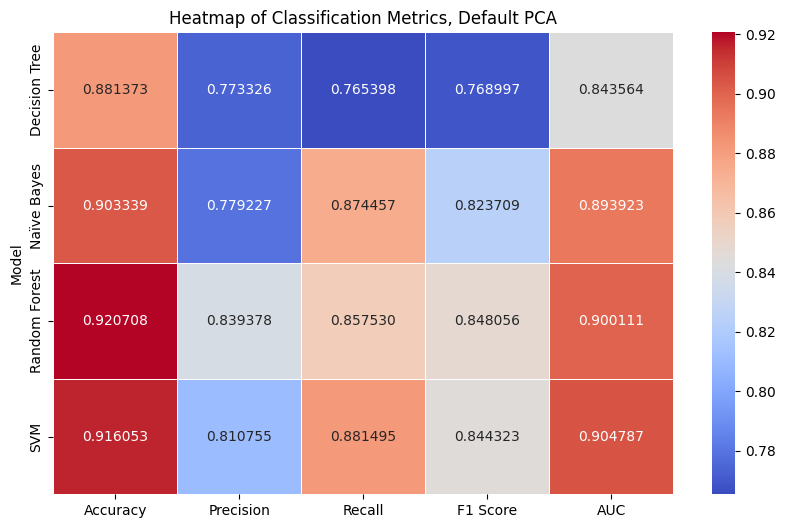

In [30]:
df_heatmap = evaluation_metrics_pca.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default PCA")
plt.show()

As observed before, we have made the study of both the SVM and Random Forest models since they show the highest values in almost all the metrics (Including the accuracy, precision, F1 score and AUC).


In [31]:
df_hyperparameter_turning.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
RANDOM FOREST GS,0.916394,0.833545,0.845436,0.839247,0.893261
RANDOM FOREST RS,0.918097,0.836612,0.849393,0.842606,0.895699
Super Vector Machine GS,0.916053,0.810755,0.881495,0.844323,0.904787
Super Vector Machine RS,0.911399,0.792667,0.890948,0.838650,0.904732


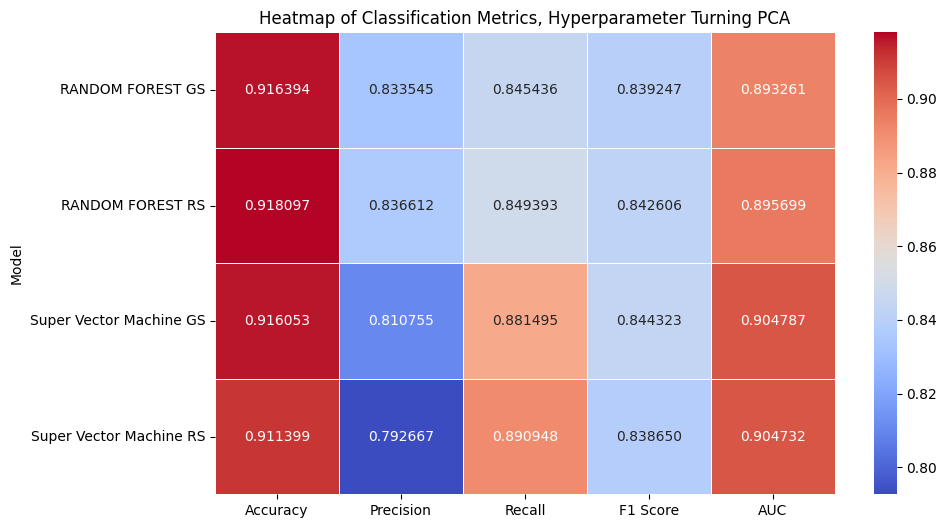

In [32]:
df_heatmap = df_hyperparameter_turning.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning PCA")
plt.show()

In the hospital context where patients are classified as alive or dead, it is crucial to ensure high model performance across all metrics, with a special emphasis on **Recall**. This metric is key to minimizing false negatives, ensuring that positive cases (patients at risk) are correctly identified, as failing to detect them could have serious consequences.

Of the models analyzed, the **SVM adjusted by Random Search (SVM RS)** is positioned as the best option. This model presents the **highest Recall (0.8909)** among all configurations, indicating its ability to identify a higher number of positive cases. Furthermore, its performance in the other metrics, such as Accuracy (~0.9114), F1 Score (~0.8387) and AUC (~0.9047), is solid and competitive, ensuring a robust overall balance.

Although the SVM fine-tuned with Grid Search (SVM GS) shows a slightly higher AUC (0.9048) and a better F1 Score, its Recall is lower (~0.8815). On the other hand, the Random Forest models, although effective, have a lower Recall (~0.8494 in RF RS), which rules them out in this case.

Therefore, the **SVM RS** is the better choice, as it prioritizes sensitivity without significantly compromising the other metrics, ensuring a safer and more effective classification in this critical environment.

### **ANALYSIS: Models obtained with data trained without using PCA**

In [33]:
# Promedios por modelo by default sin PCA, valores escalados
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
Decision Tree,0.891079,0.793762,0.781886,0.787603,0.855480
Naïve Bayes,0.886821,0.795307,0.756382,0.775189,0.844297
Random Forest,0.926780,0.872929,0.839277,0.855444,0.898254
SVM,0.920878,0.833603,0.867641,0.849957,0.903522


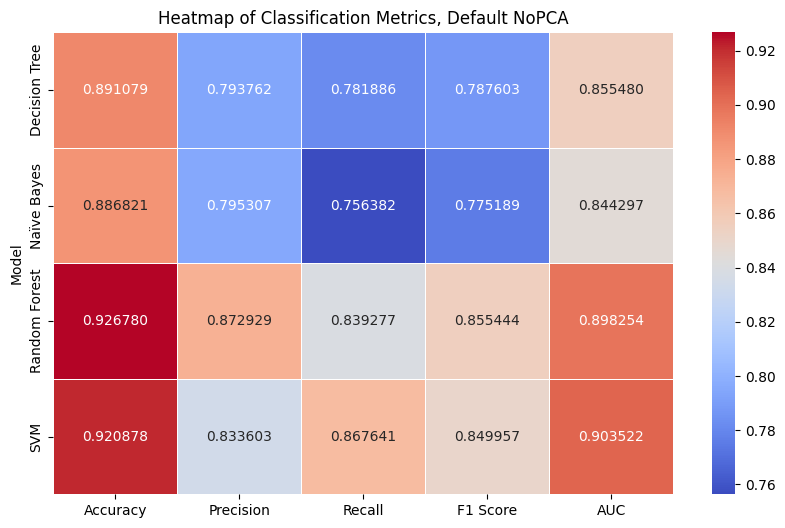

In [34]:
df_heatmap = evaluation_metrics_scaled.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default NoPCA")
plt.show()

As explained before, we have studied the models of Random Forest and SVM since they show the best classification values (The main reason for doing SVM too and not just Random Forest  model is its high  recall value, which has been explained in prior cells).

In [35]:
df_hyperparameter_turning_NoPCA.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score,AUC
Model,,,,,
RANDOM FOREST GS,0.917756,0.839606,0.843457,0.869379,0.893534
RANDOM FOREST RS,0.916621,0.829650,0.853129,0.840909,0.895922
Super Vector Machine GS,0.915429,0.821294,0.860609,0.840122,0.897558
Support Vector Machine RS,0.911343,0.792397,0.891168,0.838594,0.904765


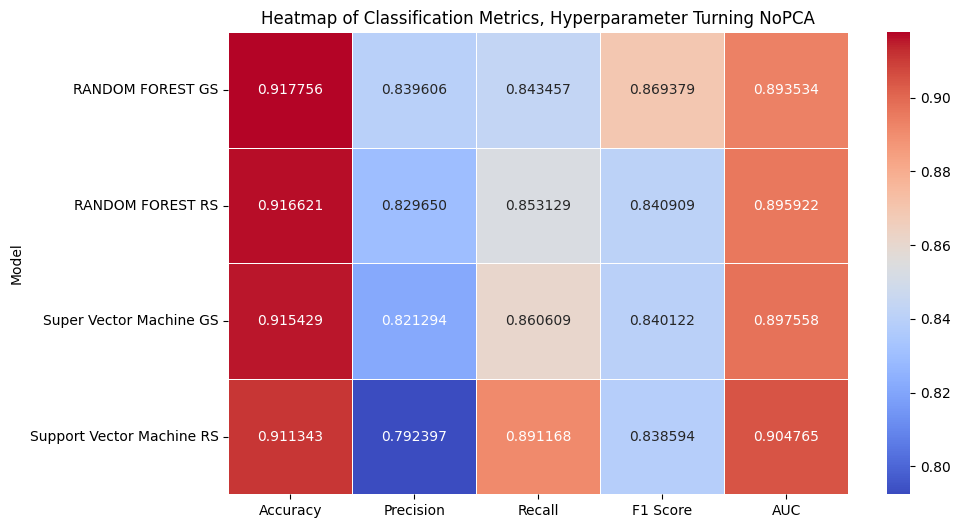

In [36]:
df_heatmap = df_hyperparameter_turning_NoPCA.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning NoPCA")
plt.show()

In the previously explained hospital context, where the classification of living or dead patients requires a model that balances all metrics but prioritizes **Recall** to minimize false negatives, models without dimensionality reduction (**No PCA**) are analyzed.

In the default configurations, the **SVM** stands out with a **Recall of 0.8676** and an excellent **AUC of 0.9035**, indicating its ability to correctly identify positive cases while maintaining a high overall quality in the classification. On the other hand, although the default **Random Forest** shows a competitive Recall (0.8392) and a good F1 Score (0.8554), it does not match the SVM in Recall or AUC, which leaves it as a secondary option.

After adjusting the hyperparameters, the **SVM RS (Random Search)** is positioned as the most suitable model. With a **Recall of 0.8912**, it is the most effective in detecting positive cases, accompanied by an **AUC of 0.9048**, the highest among all the fine-tuned models. Although the **SVM GS (Grid Search)** has a good overall performance (Recall of 0.8606), it does not reach the sensitivity of SVM RS. The fine-tuned Random Forest models do not outperform the SVM in either Recall or AUC.

Therefore, the **SVM RS** is the best choice, balancing sensitivity and robustness in this critical environment.

### **ANALYSIS: Better PCA Model vs No PCA Model**

The **SVM RS model without PCA** demonstrates a slight advantage for this hospital use case, achieving higher **Recall (0.891168)** and **AUC (0.904765)** compared to the model with PCA. These metrics are critical in a medical context, where accurate identification of positive cases (e.g. at-risk patients) is essential to minimize false negatives and ensure timely interventions.

While the differences between the two models are minimal in terms of overall performance, the improved Recall and AUC make the SVM RS model without PCA a more reliable choice. Recall directly affects the sensitivity of classification, ensuring that fewer critical cases are missed, while AUC reflects the model’s ability to balance true positives and false positives effectively.

Furthermore, by not applying PCA, the model retains the full dimensionality of the dataset, potentially preserving information that may have been lost during dimensionality reduction. This contributes to its slightly better performance in detecting positive cases.

In conclusion, the **SVM RS model without PCA** is the best choice in this delicate hospital setting. It balances solid overall performance with superior sensitivity, making it a reliable choice for critical tasks such as accurate patient classification in life-or-death situations.